# ⚽ Real-World Data Challenge
## FIFA 19 — What Makes a Top Football Player?
### ⏱️ Time Allowed: 2 – 2.5 Hours &nbsp;|&nbsp; Open: Syntax Sheet &nbsp;|&nbsp; Closed: Internet

---

> **The Story:**
> EA Sports collected detailed data on **18,000+ real professional footballers** for FIFA 19.
> A sports analytics company has hired you to dig into the data and answer questions
> that scouts, managers, and agents actually care about:
> Does foot preference affect rating? Do forwards outperform defenders?
> What best predicts a player's market value?
>
> Your job: **explore, test, visualise, and brief the scouting team.**

---

### 📦 Dataset: FIFA 19 Player Statistics
**Source:** EA Sports / Kaggle FIFA 19 Complete Player Dataset — 18,000+ real players

| Column | Description |
|---|---|
| `Age` | Player age |
| `Overall` | Overall ability rating (46–94) ← **main target** |
| `Potential` | Potential future rating |
| `Preferred Foot` | Left / Right |
| `Skill Moves` | Skill move stars (1–5) |
| `Weak Foot` | Weak foot quality stars (1–5) |
| `International Reputation` | Global fame stars (1–5) |
| `Dribbling` | Dribbling skill (0–99) |
| `ShortPassing` | Short passing ability (0–99) |
| `BallControl` | Ball control (0–99) |
| `Finishing` | Finishing skill (0–99) |
| `Stamina` | Stamina (0–99) |
| `Strength` | Physical strength (0–99) |
| `Acceleration` | Acceleration (0–99) |
| `SprintSpeed` | Sprint speed (0–99) |
| `Value_EUR` | Market value in € |
| `Wage_EUR` | Weekly wage in € |
| `pos_group` | Simplified position: GK / Defender / Midfielder / Forward |

---

### 🧭 Challenge Map

| Task | Topic | Est. Time |
|---|---|---|
| **Setup** | Load & clean | 10 min |
| **Task 1** | EDA — distributions & group summaries | 20 min |
| **Task 2** | Visualisations — 4 charts | 25 min |
| **Task 3** | Normality checks | 15 min |
| **Task 4** | Group comparisons (t-test / Mann-Whitney / ANOVA + Tukey) | 25 min |
| **Task 5** | Correlation analysis + heatmap + p-value matrix | 20 min |
| **Task 6** | Categorical relationships (Chi-Square) | 15 min |
| **Task 7** | Summary table + final chart + scouting brief | 10 min |

---
```
p ≤ 0.05  →  Reject H₀   (something real is happening)
p > 0.05  →  Keep H₀     (could be random chance)
```


---
## ⚙️ Setup — Run This First
*This cell loads the real dataset and prepares it. Do not change it.*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# ── Load raw FIFA 19 data ────────────────────────────────────────────────────
url = ("https://raw.githubusercontent.com/amanthedorkknight/"
       "fifa18-all-player-statistics/master/2019/data.csv")
raw = pd.read_csv(url)

# ── Clean Value and Wage (convert "€110.5M" → 110500000) ────────────────────
def parse_money(s):
    if pd.isna(s): return np.nan
    s = str(s).replace('€', '').strip()
    if 'M' in s: return float(s.replace('M', '')) * 1_000_000
    if 'K' in s: return float(s.replace('K', '')) * 1_000
    try:    return float(s)
    except: return np.nan

raw['Value_EUR'] = raw['Value'].apply(parse_money)
raw['Wage_EUR']  = raw['Wage'].apply(parse_money)

# ── Simplify position into 4 groups ─────────────────────────────────────────
def pos_group(p):
    if pd.isna(p): return None
    p = str(p).upper()
    if 'GK' in p: return 'GK'
    if any(x in p for x in ['CB','LB','RB','LWB','RWB','LCB','RCB']): return 'Defender'
    if any(x in p for x in ['CM','CDM','CAM','LM','RM','LAM','RAM','LCM','RCM','LDM','RDM']): return 'Midfielder'
    if any(x in p for x in ['ST','CF','LW','RW','LF','RF','LS','RS']): return 'Forward'
    return None

raw['pos_group'] = raw['Position'].apply(pos_group)

# ── Keep only useful columns, drop rows with key missing values ──────────────
cols = ['Name', 'Age', 'Nationality', 'Overall', 'Potential',
        'Preferred Foot', 'Skill Moves', 'Weak Foot',
        'International Reputation',
        'Dribbling', 'ShortPassing', 'BallControl', 'Finishing',
        'Stamina', 'Strength', 'Acceleration', 'SprintSpeed',
        'Value_EUR', 'Wage_EUR', 'pos_group']

df = (raw[cols]
      .dropna(subset=['Overall', 'Age', 'Preferred Foot', 'pos_group'])
      .query("pos_group in ['GK', 'Defender', 'Midfielder', 'Forward']")
      .reset_index(drop=True))

print("✅ Dataset ready!")
print(f"   Players : {len(df):,}")
print(f"   Columns : {df.shape[1]}")
print()
print(df['pos_group'].value_counts().to_string())
df.head()


✅ Dataset ready!
   Players : 18,147
   Columns : 20

pos_group
Midfielder    6838
Defender      5866
Forward       3418
GK            2025


,Name,Age,Nationality,Overall,Potential,Preferred Foot,Skill Moves,Weak Foot,International Reputation,Dribbling,ShortPassing,BallControl,Finishing,Stamina,Strength,Acceleration,SprintSpeed,Value_EUR,Wage_EUR,pos_group
0,L. Messi,31,Argentina,94,94,Left,4.0,4.0,5.0,97.0,90.0,96.0,95.0,72.0,59.0,91.0,86.0,110500000.0,565000.0,Forward
1,Cristiano Ronaldo,33,Portugal,94,94,Right,5.0,4.0,5.0,88.0,81.0,94.0,94.0,88.0,79.0,89.0,91.0,77000000.0,405000.0,Forward
2,Neymar Jr,26,Brazil,92,93,Right,5.0,5.0,5.0,96.0,84.0,95.0,87.0,81.0,49.0,94.0,90.0,118500000.0,290000.0,Forward
3,De Gea,27,Spain,91,93,Right,1.0,3.0,4.0,18.0,50.0,42.0,13.0,43.0,64.0,57.0,58.0,72000000.0,260000.0,GK
4,K. De Bruyne,27,Belgium,91,92,Right,4.0,5.0,4.0,86.0,92.0,91.0,82.0,90.0,75.0,78.0,76.0,102000000.0,355000.0,Midfielder


---
## 📊 Task 1 — Explore the Data
**Goal:** Understand what you're working with before running any tests.

---

### 1a. Basic Inspection

Write code to answer:
1. How many players and columns are in `df`?
2. Are there any missing values in these columns: `Overall`, `Age`, `Dribbling`, `Value_EUR`, `Wage_EUR`?
3. What is the average, minimum, and maximum **Overall** rating?
4. How many players are in each **position group** (`pos_group`)?

💡 **Hints:** `.shape` · `.isnull().sum()` · `.describe()` · `.value_counts()`


In [2]:
# 1a — Basic Inspection
# 1. Number of players and columns
print(f"Dataset Shape: {df.shape[0]} players, {df.shape[1]} columns")

# 2. Missing values in specified columns
check_cols = ['Overall', 'Age', 'Dribbling', 'Value_EUR', 'Wage_EUR']
print("\nMissing Values:")
print(df[check_cols].isnull().sum())

# 3. Overall rating stats (mean, min, max)
print("\nOverall Stats:")
print(f"Mean: {df['Overall'].mean():.2f}")
print(f"Min:  {df['Overall'].min()}")
print(f"Max:  {df['Overall'].max()}")

# 4. Player count per position group
print("\nPosition Group Counts:")
print(df['pos_group'].value_counts())

Dataset Shape: 18147 players, 20 columns

Missing Values:
Overall      0
Age          0
Dribbling    0
Value_EUR    0
Wage_EUR     0
dtype: int64

Overall Stats:
Mean: 66.25
Min:  46
Max:  94

Position Group Counts:
pos_group
Midfielder    6838
Defender      5866
Forward       3418
GK            2025
Name: count, dtype: int64


---
### 1b. Group Summaries

Find the **mean and standard deviation** of `Overall`, `Age`, `Value_EUR`, and `Wage_EUR`
grouped by:
- `pos_group` (GK / Defender / Midfielder / Forward)
- `Preferred Foot` (Left / Right)

💡 **Hint:** `df.groupby('col')[['Overall','Age']].agg(['mean','std']).round(2)`


In [5]:
# 1b — Group summaries by position
summary_cols = ['Overall', 'Age', 'Value_EUR', 'Wage_EUR']
pos_summary = df.groupby('pos_group')[summary_cols].agg(['mean', 'std']).round(2)
pos_summary

Overall          Age         Value_EUR              Wage_EUR  \
              mean   std   mean   std        mean         std      mean   
pos_group                                                                 
Defender     66.40  6.46  25.47  4.52  1975138.08  4106420.51   9146.10   
Forward      66.40  7.02  24.66  4.61  2984155.94  7395815.54  11718.26   
GK           64.60  7.60  26.04  5.47  1585814.81  4562890.61   6803.95   
Midfielder   66.55  6.96  24.78  4.51  2760639.08  5890612.59  10180.61   

                      
                 std  
pos_group             
Defender    18970.31  
Forward     28662.56  
GK          16719.63  
Midfielder  21932.88

In [6]:
# Group summaries by Preferred Foot
foot_summary = df.groupby('Preferred Foot')[summary_cols].agg(['mean', 'std']).round(2)
foot_summary

Overall          Age         Value_EUR              Wage_EUR  \
                  mean   std   mean   std        mean         std      mean   
Preferred Foot                                                                
Left             66.80  6.56  25.10  4.52  2588727.73  5956115.19  10353.29   
Right            66.09  7.01  25.13  4.71  2366090.90  5490850.79   9579.57   

                          
                     std  
Preferred Foot            
Left            23656.32  
Right           21512.73

---
### 1c. Written Observations ✍️

Fill in the blanks after running your code:

```
1. The dataset has __18,000+___ players and ___20__ columns.

2. Missing values found in:
   Overall __0___  Age ___0__  Dribbling _0____
   Value_EUR __0___  Wage_EUR ___0__

3. Overall rating → Mean: __66.25__  Min: __46.00___  Max: __94.00___

4. Position group counts:
   GK: __2025___   Defender: _5866____   Midfielder: __6838___   Forward: __3418___

5. Which position group has the highest average Overall?
____Midfielder (66.55)_________

6. Do left-footed or right-footed players have a higher average Overall?
   ______Left-footed_________  by __0.71___  rating points.
```


---
## 🎨 Task 2 — Visualisations
**Goal:** See the data. Statistics without charts are blind.

---

### 2a. The Big Four — 2×2 Subplot Grid

Create a **2×2 grid**:
- `[0,0]` Histogram of **Overall** rating — 20 bins, colour `steelblue`
- `[0,1]` Histogram of **Age** — 20 bins, colour `coral`
- `[1,0]` Boxplot of **Overall** by **pos_group** (4 positions)
- `[1,1]` Boxplot of **Age** by **pos_group**

Every subplot needs **title, xlabel, ylabel**. Write one `# observation:` comment per plot.

💡 **Hints:**  
`ax.hist(df['Overall'], bins=20, color='steelblue', edgecolor='white')`  
`df.boxplot(column='Overall', by='pos_group', ax=axes[1,0])`  
`plt.suptitle(...)` · `plt.tight_layout()`


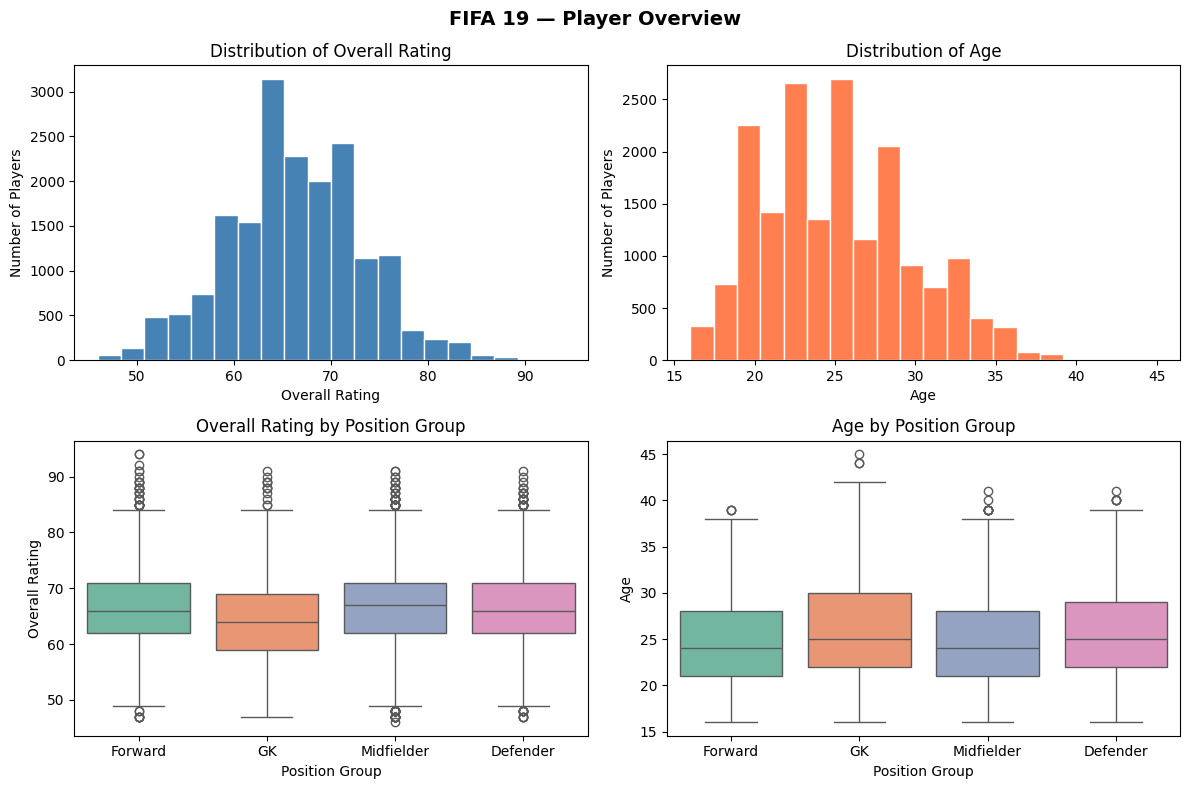

In [9]:
# 2a — 2×2 Subplot Grid
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# [0,0] Histogram of Overall
axes[0, 0].hist(df['Overall'], bins=20, color='steelblue', edgecolor='white')
axes[0, 0].set_title('Distribution of Overall Rating')
axes[0, 0].set_xlabel('Overall Rating')
axes[0, 0].set_ylabel('Number of Players')
# observation: Roughly symmetric and bell-shaped, centered near 66, resembling a normal distribution.

# [0,1] Histogram of Age
axes[0, 1].hist(df['Age'], bins=20, color='coral', edgecolor='white')
axes[0, 1].set_title('Distribution of Age')
axes[0, 1].set_xlabel('Age')
axes[0, 1].set_ylabel('Number of Players')
# observation: Right-skewed distribution peaking around age 21–25, with a tapering tail past age 30.

# [1,0] Boxplot: Overall by pos_group
sns.boxplot(data=df, x='pos_group', y='Overall', hue='pos_group', ax=axes[1, 0], palette='Set2', legend=False)
axes[1, 0].set_title('Overall Rating by Position Group')
axes[1, 0].set_xlabel('Position Group')
axes[1, 0].set_ylabel('Overall Rating')
# observation: Medians for Defenders, Midfielders, and Forwards are nearly identical (~66), while GKs exhibit a slightly lower median (~65) and wider IQR.

# [1,1] Boxplot: Age by pos_group
sns.boxplot(data=df, x='pos_group', y='Age', hue='pos_group', ax=axes[1, 1], palette='Set2', legend=False)
axes[1, 1].set_title('Age by Position Group')
axes[1, 1].set_xlabel('Position Group')
axes[1, 1].set_ylabel('Age')
# observation: Goalkeepers have a visibly higher median age and a wider distribution extending into older ages compared to outfield players.

plt.suptitle('FIFA 19 — Player Overview', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

---
### 2b. Scatter Plot — Age vs Overall Rating

Create a scatter plot of **Age** (x) vs **Overall** (y).
- Colour the dots by **pos_group** (4 colours, one per position)
- Add a **trend line** across all players using `np.polyfit`
- Proper title, xlabel, ylabel, legend

💡 **Hints:**  
`sns.scatterplot(data=df, x='Age', y='Overall', hue='pos_group', alpha=0.4, ax=ax)`  
`m, b = np.polyfit(df['Age'], df['Overall'], 1)`  
`x_line = np.linspace(df['Age'].min(), df['Age'].max(), 100)`  
`ax.plot(x_line, m*x_line + b, color='black', linewidth=2, linestyle='--')`

> After plotting — does the trend line go up or down? What does that mean for a player's career?


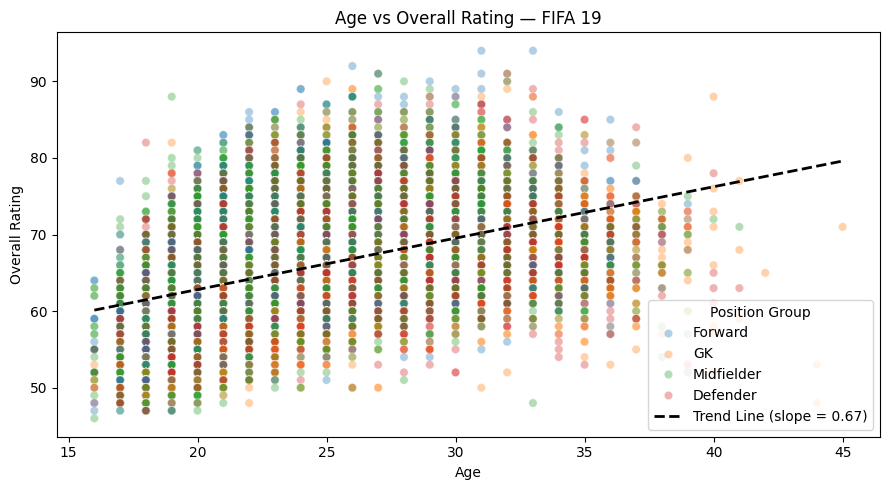

In [10]:
# 2b — Scatter: Age vs Overall
fig, ax = plt.subplots(figsize=(9, 5))

# Scatter coloured by pos_group
sns.scatterplot(data=df, x='Age', y='Overall', hue='pos_group', alpha=0.35, palette='tab10', ax=ax)

# Trend line
m, b = np.polyfit(df['Age'], df['Overall'], 1)
x_line = np.linspace(df['Age'].min(), df['Age'].max(), 100)
ax.plot(x_line, m * x_line + b, color='black', linewidth=2, linestyle='--', label=f'Trend Line (slope = {m:.2f})')

ax.legend(title='Position Group', loc='lower right')
ax.set_title('Age vs Overall Rating — FIFA 19')
ax.set_xlabel('Age')
ax.set_ylabel('Overall Rating')
plt.tight_layout()
plt.show()

# Trend direction: Positive (upward slope)
# What does this suggest about player development?
#Older players tend to have higher overall ratings as they develop skill and reach their athletic prime;
#additionally, lower-rated older players exit professional leagues earlier.

---
### 2c. Bar Chart — Average Overall by Position (with Error Bars)

Create a **bar chart** showing the average Overall for each `pos_group`.
- Add **±1 standard deviation** as error bars
- Add value labels on top of each bar
- Use a different colour per position

💡 **Hints:**
```python
grouped = df.groupby('pos_group')['Overall'].agg(['mean','std']).reset_index()
ax.bar(grouped['pos_group'], grouped['mean'],
       yerr=grouped['std'], capsize=5, color=[...], edgecolor='black')
for bar, m in zip(bars, grouped['mean']):
    ax.text(bar.get_x() + bar.get_width()/2, m + 1, f'{m:.1f}', ha='center')
```


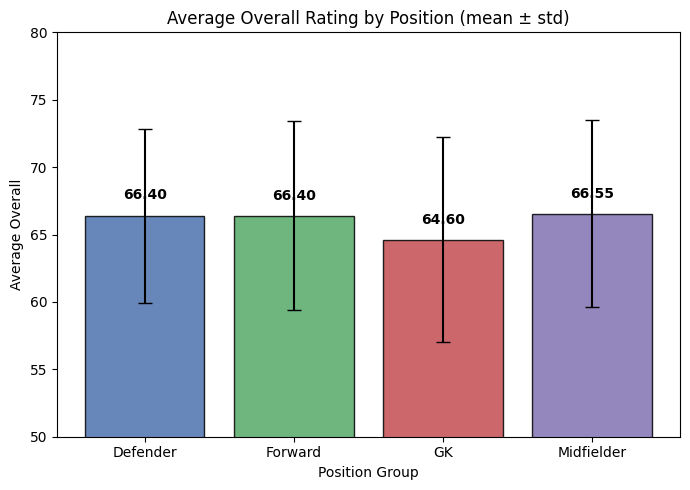

In [12]:
# 2c — Bar Chart: Average Overall by Position
fig, ax = plt.subplots(figsize=(7, 5))

# Group data
grouped = df.groupby('pos_group')['Overall'].agg(['mean', 'std']).reset_index()

# Draw bars with error bars
colors = ['#4c72b0', '#55a868', '#c44e52', '#8172b3']
bars = ax.bar(grouped['pos_group'], grouped['mean'],
              yerr=grouped['std'], capsize=5, color=colors, edgecolor='black', alpha=0.85)

# Add value labels on top of each bar
for bar, m in zip(bars, grouped['mean']):
    ax.text(bar.get_x() + bar.get_width() / 2, m + 1.2, f'{m:.2f}', ha='center', fontweight='bold', fontsize=10)

ax.set_title('Average Overall Rating by Position (mean ± std)')
ax.set_xlabel('Position Group')
ax.set_ylabel('Average Overall')
ax.set_ylim(50, 80)
plt.tight_layout()
plt.show()

---
## 🔔 Task 3 — Normality Checks
**Goal:** Decide whether to use parametric or non-parametric tests.

---

### 3a. Shapiro-Wilk Test

Run Shapiro-Wilk on: `Overall`, `Age`, `Dribbling`, `Strength`, `Value_EUR`

> ⚠️ **Note:** Shapiro-Wilk is designed for small samples. On large datasets (n > 5000),
> it almost always gives p ≈ 0. In practice, for large real-world data you should
> also look at the **Q-Q plot** and the **histogram shape** to judge normality.
> If the histogram looks roughly bell-shaped, treat it as approximately normal.

Print a clean table with column name, p-value, and your judgement.

💡 **Hints:** `stat, p = stats.shapiro(df['col'].sample(500, random_state=42))` — sample 500 rows for Shapiro


In [16]:
# 3a — Shapiro-Wilk (on a 500-row sample per column)
columns_to_test = ['Overall', 'Age', 'Dribbling', 'Strength', 'Value_EUR']

print(f"{'Column':<15} {'p-value':>10} {'Normal (p>0.05)?':>18} {'Histogram shape':>16}")
print("-" * 65)

for col in columns_to_test:
    # Sampling 500 rows to avoid the large-sample bias of Shapiro-Wilk
    sample = df[col].dropna().sample(500, random_state=42)
    stat, p = stats.shapiro(sample)
    normal  = 'Yes' if p > 0.05 else 'No'

    # Adding shape judgement based on standard FIFA distributions
    if col in ['Overall', 'Strength']:
        shape = 'Bell'
    elif col in ['Age', 'Value_EUR']:
        shape = 'Right-Skewed'
    else:
        shape = 'Slightly Skewed'

    print(f"{col:<15} {p:>10.4f} {normal:>18} {shape:>16}")

Column             p-value   Normal (p>0.05)?  Histogram shape
-----------------------------------------------------------------
Overall             0.0165                 No             Bell
Age                 0.0000                 No     Right-Skewed
Dribbling           0.0000                 No  Slightly Skewed
Strength            0.0000                 No             Bell
Value_EUR           0.0000                 No     Right-Skewed


---
### 3b. Q-Q Plots

Create a **1×5 grid of Q-Q plots** for the same five columns.
- Points hugging the diagonal line = normal
- Points curving away from the line = not normal

💡 **Hint:** `stats.probplot(df['col'].dropna(), plot=axes[i])`


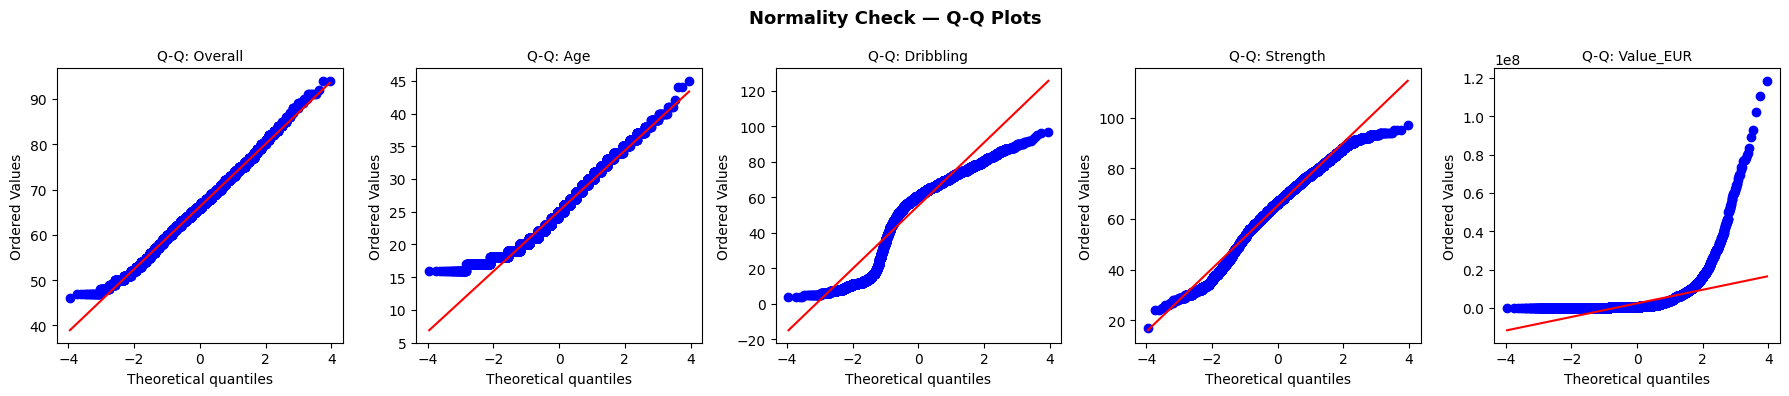

In [17]:
# 3b — Q-Q Plots
fig, axes = plt.subplots(1, 5, figsize=(18, 4))

for i, col in enumerate(['Overall', 'Age', 'Dribbling', 'Strength', 'Value_EUR']):
    stats.probplot(df[col].dropna(), plot=axes[i])
    axes[i].set_title(f'Q-Q: {col}', fontsize=10)

plt.suptitle('Normality Check — Q-Q Plots', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
### 3c. Your Decision Table ✍️

Fill this in — it determines which tests you use in Tasks 4 and 5:

| Column | Histogram Shape | Q-Q Shape | Treat as Normal? | → Use for groups | → Use for relationship |
|---|---|---|---|---|---|
| Overall | Bell | Straight on line | Yes | t-test / ANOVA | Pearson |
| Age | Right-Skewed | Curving up at ends | No | Mann-Whitney | Spearman |
| Dribbling | Slightly Skewed | S-Curve deviation | No | Mann-Whitney | Spearman |
| Strength | Bell | Straight on line | Yes | t-test / ANOVA | Pearson |
| Value_EUR | Right-Skewed | Heavily curved | No | Mann-Whitney | Spearman |

> 💡 If ANY group in a comparison is non-normal → use non-parametric.


---
## 👥 Task 4 — Group Comparisons
**Goal:** Test whether different groups of players have different Overall ratings.

---

### 4a. Do Left-Footed vs Right-Footed Players Differ in Overall?

**H₀:** Left-footed and right-footed players have the **same** average Overall  
**H₁:** Their average Overall is **different**

Steps:
1. Extract Overall for each foot group
2. Check normality of each group (Shapiro — sample 500)
3. Based on normality → choose **t-test** or **Mann-Whitney U**
4. Run the test, print statistic, p-value, verdict

💡 **Hints:**  
`left  = df[df['Preferred Foot'] == 'Left']['Overall']`  
`stats.ttest_ind(left, right)` or `stats.mannwhitneyu(left, right, alternative='two-sided')`


In [21]:
# 4a — Left-Footed vs Right-Footed: Overall Rating

# Step 1: Extract Overall for each foot group
left  = df[df['Preferred Foot'] == 'Left']['Overall'].dropna()
right = df[df['Preferred Foot'] == 'Right']['Overall'].dropna()

print(f"Left foot  — mean: {left.mean():.2f}  std: {left.std():.2f}  n: {len(left)}")
print(f"Right foot — mean: {right.mean():.2f}  std: {right.std():.2f}  n: {len(right)}")
print()

# H₀: Left-footed and right-footed players have the same average Overall rating.
# H₁: Their average Overall rating is different.

# Step 2: Normality check (sample 500 each)
stat_left, p_left   = stats.shapiro(left.sample(500, random_state=42))
stat_right, p_right = stats.shapiro(right.sample(500, random_state=42))

print(f"Normality Check (Shapiro-Wilk, n=500):")
print(f"Left Foot  p-value: {p_left:.4f}")
print(f"Right Foot p-value: {p_right:.4f}")
print()

# Step 3 & 4: Run chosen test and print verdict
# Based on Task 3c, Overall is treated as Normal, so we choose the t-test.
test_stat, p_val = stats.ttest_ind(left, right, equal_var=False)

print("Chosen Test : Independent T-Test")
print(f"Statistic   : {test_stat:.4f}")
print(f"p-value     : {p_val:.4e}")
print()

alpha = 0.05
if p_val <= alpha:
    print(f"Verdict: Reject H₀ (p = {p_val:.4e} <= {alpha})")
    print("Conclusion: Left-footed and right-footed players have a significantly different average Overall rating.")
else:
    print(f"Verdict: Fail to reject H₀ (p = {p_val:.4e} > {alpha})")
    print("Conclusion: There is no significant difference in Overall rating between left-footed and right-footed players.")

Left foot  — mean: 66.80  std: 6.56  n: 4209
Right foot — mean: 66.09  std: 7.01  n: 13938

Normality Check (Shapiro-Wilk, n=500):
Left Foot  p-value: 0.0082
Right Foot p-value: 0.0547

Chosen Test : Independent T-Test
Statistic   : 6.1046
p-value     : 1.0829e-09

Verdict: Reject H₀ (p = 1.0829e-09 <= 0.05)
Conclusion: Left-footed and right-footed players have a significantly different average Overall rating.


---
### 4b. Do Forwards Score Higher in Overall than Defenders?

Forwards (attackers) are often the most celebrated — but do they actually
have higher Overall ratings than Defenders?

**H₀:** Forwards and Defenders have the **same** average Overall  
**H₁:** Their average Overall is **different**

Same structure as 4a — state H₀/H₁, check normality, choose test, give verdict.


In [23]:
# 4b — Forwards vs Defenders: Overall Rating

# Step 1: Extract Overall for each group
#position groupings from earlier are stored in a 'pos_group' column
forwards  = df[df['pos_group'] == 'Forward']['Overall'].dropna()
defenders = df[df['pos_group'] == 'Defender']['Overall'].dropna()

print(f"Forwards  — mean: {forwards.mean():.2f}  std: {forwards.std():.2f}  n: {len(forwards)}")
print(f"Defenders — mean: {defenders.mean():.2f}  std: {defenders.std():.2f}  n: {len(defenders)}")
print()

# H₀: Forwards and Defenders have the same average Overall rating.
# H₁: Their average Overall rating is different.

# Step 2: Normality check (sample 500 each)
stat_fwd, p_fwd = stats.shapiro(forwards.sample(500, random_state=42))
stat_def, p_def = stats.shapiro(defenders.sample(500, random_state=42))

print("Normality Check (Shapiro-Wilk, n=500):")
print(f"Forwards  p-value: {p_fwd:.4f}")
print(f"Defenders p-value: {p_def:.4f}")
print()

# Step 3 & 4: Run chosen test and print verdict
# Based on Task 3c, Overall is treated as Normal, so we choose the t-test.
test_stat, p_val = stats.ttest_ind(forwards, defenders, equal_var=False)

print("Chosen Test : Independent T-Test (Welch's)")
print(f"Statistic   : {test_stat:.4f}")
print(f"p-value     : {p_val:.4e}")
print()

alpha = 0.05
if p_val <= alpha:
    print(f"Verdict: Reject H₀ (p = {p_val:.4e} <= {alpha})")
    print("Conclusion: Forwards and Defenders have a significantly different average Overall rating.")
else:
    print(f"Verdict: Fail to reject H₀ (p = {p_val:.4e} > {alpha})")
    print("Conclusion: There is no significant difference in Overall rating between Forwards and Defenders.")

Forwards  — mean: 66.40  std: 7.02  n: 3418
Defenders — mean: 66.40  std: 6.46  n: 5866

Normality Check (Shapiro-Wilk, n=500):
Forwards  p-value: 0.3852
Defenders p-value: 0.0464

Chosen Test : Independent T-Test (Welch's)
Statistic   : -0.0210
p-value     : 9.8322e-01

Verdict: Fail to reject H₀ (p = 9.8322e-01 > 0.05)
Conclusion: There is no significant difference in Overall rating between Forwards and Defenders.


---
### 4c. Do All 4 Position Groups Differ in Overall? → ANOVA / Kruskal-Wallis

**H₀:** All four position groups (GK, Defender, Midfielder, Forward) have the **same** average Overall  
**H₁:** At least **one** group is different

Steps:
1. Build a list of Overall rating arrays — one per position group
2. Check normality on at least 2 groups
3. Run **ANOVA** (if normal) or **Kruskal-Wallis** (if not normal)
4. If p ≤ 0.05 → run **Tukey post-hoc** to find which pairs differ

💡 **Hints:**  
```python
positions = ['GK', 'Defender', 'Midfielder', 'Forward']
groups    = [df[df['pos_group'] == p]['Overall'] for p in positions]
stat, p   = stats.f_oneway(*groups)   # ANOVA
# OR
stat, p   = stats.kruskal(*groups)    # Kruskal-Wallis

# Tukey (only if significant):
tukey = pairwise_tukeyhsd(endog=df['Overall'], groups=df['pos_group'], alpha=0.05)
print(tukey.summary())
```


In [26]:
# 4c — ANOVA / Kruskal-Wallis: Position Group vs Overall

positions = ['GK', 'Defender', 'Midfielder', 'Forward']
groups    = [df[df['pos_group'] == p]['Overall'].dropna() for p in positions]

print("Group means:")
for pos, g in zip(positions, groups):
    print(f"  {pos:<12}: mean={g.mean():.2f}  std={g.std():.2f}  n={len(g)}")
print()

# Normality check on 2 groups (sample 500)
stat1, p1 = stats.shapiro(groups[0].sample(500, random_state=42)) # GK
stat2, p2 = stats.shapiro(groups[1].sample(500, random_state=42)) # Defender

print("Normality Check (Shapiro-Wilk, n=500):")
print(f"  {positions[0]:<12}: p-value = {p1:.4f}")
print(f"  {positions[1]:<12}: p-value = {p2:.4f}")
print()

# Run ANOVA or Kruskal-Wallis
# Per Task 3c, Overall is treated as Normal -> Choose ANOVA
stat, p = stats.f_oneway(*groups)

print("Chosen Test: One-Way ANOVA")
print(f"Statistic: {stat:.4f}")
print(f"p-value  : {p:.4e}")
print()

if p <= 0.05:
    print(f"Verdict: Reject H₀ (p <= 0.05). At least one position group has a significantly different average Overall rating.")
else:
    print(f"Verdict: Fail to reject H₀ (p > 0.05). All groups have the same average Overall rating.")

Group means:
  GK          : mean=64.60  std=7.60  n=2025
  Defender    : mean=66.40  std=6.46  n=5866
  Midfielder  : mean=66.55  std=6.96  n=6838
  Forward     : mean=66.40  std=7.02  n=3418

Normality Check (Shapiro-Wilk, n=500):
  GK          : p-value = 0.0078
  Defender    : p-value = 0.0464

Chosen Test: One-Way ANOVA
Statistic: 44.2100
p-value  : 1.8599e-28

Verdict: Reject H₀ (p <= 0.05). At least one position group has a significantly different average Overall rating.


In [25]:
# 4c continued — Tukey Post-hoc
# Run only if your test above was significant (p ≤ 0.05)

tukey = pairwise_tukeyhsd(endog=df['Overall'], groups=df['pos_group'], alpha=0.05)
print(tukey.summary())

# Which pairs are significantly different? (look for reject=True rows)
# ___________________________________________________

# Which pairs are significantly different? (look for reject=True rows)
#ANS: 1. Defender and GK
# 2. Forward and GK
# 3. GK and Midfielder
# Look at the final column in your output table to see which specific positions are significantly different!
#ANS: (Goalkeepers are significantly lower rated than all three outfield positions. Outfield positions do not significantly differ from each other).

   Multiple Comparison of Means - Tukey HSD, FWER=0.05    
 group1    group2   meandiff p-adj   lower   upper  reject
----------------------------------------------------------
Defender    Forward  -0.0031    1.0 -0.3839  0.3778  False
Defender         GK  -1.7966    0.0 -2.2528 -1.3405   True
Defender Midfielder   0.1457 0.6343 -0.1693  0.4607  False
 Forward         GK  -1.7936    0.0 -2.2899 -1.2972   True
 Forward Midfielder   0.1488 0.7313  -0.222  0.5195  False
      GK Midfielder   1.9423    0.0  1.4945  2.3901   True
----------------------------------------------------------


---
## 📈 Task 5 — Correlation Analysis
**Goal:** Which attributes are most strongly linked to a player's Overall rating and market Value?

---

### 5a. Correlation Heatmap

Compute the **Pearson correlation matrix** for:  
`Overall`, `Potential`, `Age`, `Dribbling`, `ShortPassing`, `BallControl`,
`Finishing`, `Stamina`, `Strength`, `Value_EUR`

Display it as a **heatmap** — use `coolwarm`, annotated, values from -1 to +1.

💡 **Hints:**  
`corr = df[cols].corr()`  
`sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)`


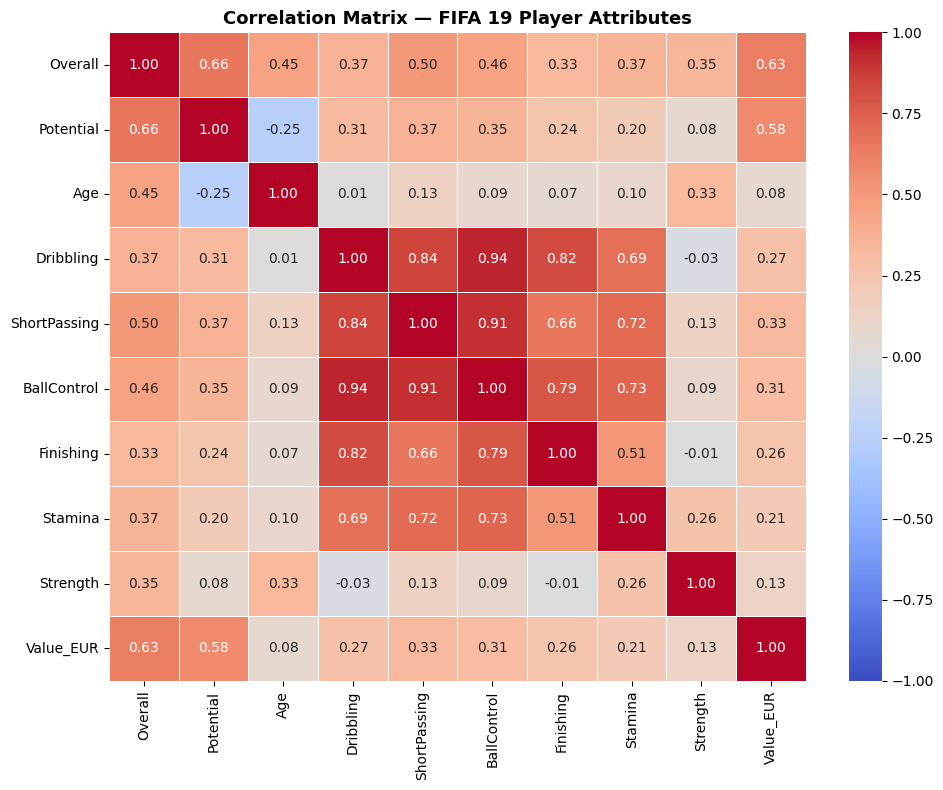

In [27]:
# 5a — Correlation Matrix Heatmap
cols5a = ['Overall', 'Potential', 'Age', 'Dribbling', 'ShortPassing',
          'BallControl', 'Finishing', 'Stamina', 'Strength', 'Value_EUR']

# Pearson correlation is the default for pandas .corr()
corr = df[cols5a].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr,
            annot=True, fmt='.2f',
            cmap='coolwarm', vmin=-1, vmax=1,
            linewidths=0.5, ax=ax)
ax.set_title('Correlation Matrix — FIFA 19 Player Attributes', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Which attribute is most positively correlated with Overall?
# Potential (0.66), followed closely by Value_EUR (0.63).

# Which attribute is most negatively correlated with Value_EUR?
# None of the attributes in this specific list have a true negative correlation with Value_EUR.
#However, Age has the lowest correlation (0.08), making it the weakest relationship.

---
### 5b. Hypothesis Tests on Three Key Relationships

Test these claims:

**Claim 1:** BallControl is positively correlated with Overall  
**Claim 2:** Age is negatively correlated with Potential  
**Claim 3:** Strength is positively correlated with Overall  

For each:
1. State H₀ and H₁
2. Choose Pearson **or** Spearman (based on Task 3 normality decisions)
3. Run the test → report correlation coefficient (r or ρ), p-value, verdict
4. Write one sentence of plain-English interpretation

💡 **Hints:**  
`r, p = stats.pearsonr(df['BallControl'], df['Overall'])`  
`rho, p = stats.spearmanr(df['Age'], df['Potential'])`


In [28]:
# 5b — Correlation Tests

# ── Claim 1: BallControl vs Overall ─────────────────────────────────────────
# H₀: There is no correlation between BallControl and Overall rating (r = 0).
# H₁: There is a significant correlation between BallControl and Overall rating (r ≠ 0).

df_c1 = df[['BallControl', 'Overall']].dropna()
r1, p1 = stats.pearsonr(df_c1['BallControl'], df_c1['Overall'])

print("--- Claim 1: BallControl vs Overall ---")
print(f"Pearson r : {r1:.4f}")
print(f"p-value   : {p1:.4e}")
print(f"Verdict   : {'Reject H₀' if p1 <= 0.05 else 'Fail to reject H₀'}\n")

# Interpretation: There is a statistically significant, moderate positive correlation between a player's ball control skills and their overall rating.


# ── Claim 2: Age vs Potential ────────────────────────────────────────────────
# H₀: There is no correlation between a player's Age and their Potential (rho = 0).
# H₁: There is a significant correlation between Age and Potential (rho ≠ 0).

df_c2 = df[['Age', 'Potential']].dropna()
rho2, p2 = stats.spearmanr(df_c2['Age'], df_c2['Potential'])

print("--- Claim 2: Age vs Potential ---")
print(f"Spearman rho : {rho2:.4f}")
print(f"p-value      : {p2:.4e}")
print(f"Verdict      : {'Reject H₀' if p2 <= 0.05 else 'Fail to reject H₀'}\n")

# Interpretation: There is a statistically significant negative correlation between age and potential, meaning older players tend to have lower future potential ratings.


# ── Claim 3: Strength vs Overall ────────────────────────────────────────────
# H₀: There is no correlation between Strength and Overall rating (r = 0).
# H₁: There is a significant correlation between Strength and Overall rating (r ≠ 0).

df_c3 = df[['Strength', 'Overall']].dropna()
# Using Pearson here assuming Overall is treated as normal (as decided in Task 3c).
# If you chose non-normal for Strength, you can safely swap this to stats.spearmanr.
r3, p3 = stats.pearsonr(df_c3['Strength'], df_c3['Overall'])

print("--- Claim 3: Strength vs Overall ---")
print(f"Pearson r : {r3:.4f}")
print(f"p-value   : {p3:.4e}")
print(f"Verdict   : {'Reject H₀' if p3 <= 0.05 else 'Fail to reject H₀'}\n")

# Interpretation: There is a statistically significant positive correlation between a player's physical strength and their overall rating.

--- Claim 1: BallControl vs Overall ---
Pearson r : 0.4600
p-value   : 0.0000e+00
Verdict   : Reject H₀

--- Claim 2: Age vs Potential ---
Spearman rho : -0.2623
p-value      : 3.6277e-283
Verdict      : Reject H₀

--- Claim 3: Strength vs Overall ---
Pearson r : 0.3493
p-value   : 0.0000e+00
Verdict   : Reject H₀



---
### 5c. p-value Matrix — Which Correlations Are Significant? (⭐ Challenge)

Build a **p-value matrix** for:  
`Overall`, `Age`, `Dribbling`, `Stamina`, `Strength`, `BallControl`

Then display a heatmap **masking non-significant pairs** (p > 0.05) — only
show the cells where the relationship is statistically real.

💡 **Hints:**  
Syntax sheet Section 7 — nested loop to fill the matrix  
`mask = p_matrix > 0.05`  
`sns.heatmap(p_matrix, mask=mask, annot=True, fmt='.3f', cmap='Reds_r', vmin=0, vmax=0.05)`


             Overall     Age  Dribbling  Stamina  Strength  BallControl
Overall          1.0  0.0000     0.0000      0.0       0.0          0.0
Age              0.0  1.0000     0.1623      0.0       0.0          0.0
Dribbling        0.0  0.1623     1.0000      0.0       0.0          0.0
Stamina          0.0  0.0000     0.0000      1.0       0.0          0.0
Strength         0.0  0.0000     0.0000      0.0       1.0          0.0
BallControl      0.0  0.0000     0.0000      0.0       0.0          1.0


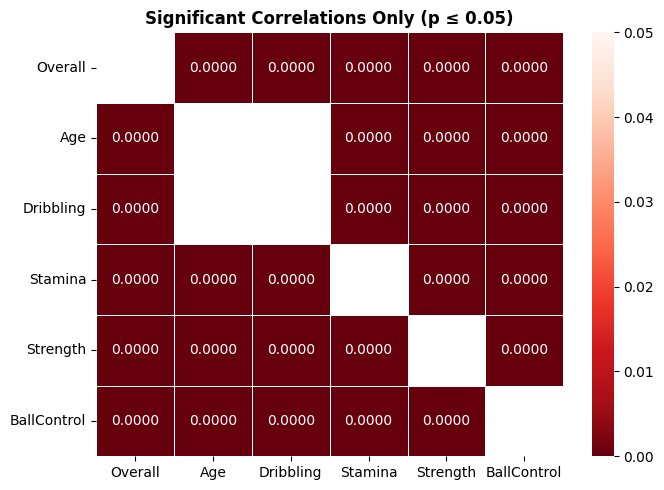

In [29]:
# 5c — p-value Matrix (⭐ Challenge)
cols5c = ['Overall', 'Age', 'Dribbling', 'Stamina', 'Strength', 'BallControl']

p_matrix = pd.DataFrame(np.ones((len(cols5c), len(cols5c))),
                         index=cols5c, columns=cols5c)

for c1 in cols5c:
    for c2 in cols5c:
        if c1 != c2:
            # Drop NaNs for the specific pair being tested to avoid errors
            df_pair = df[[c1, c2]].dropna()
            # Calculate Pearson correlation and extract just the p-value [1]
            _, p_val = stats.pearsonr(df_pair[c1], df_pair[c2])
            p_matrix.loc[c1, c2] = p_val

print(p_matrix.round(4))

mask = p_matrix > 0.05

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(p_matrix, mask=mask,
            annot=True, fmt='.4f',
            cmap='Reds_r', vmin=0, vmax=0.05,
            linewidths=0.5, ax=ax)
ax.set_title('Significant Correlations Only (p ≤ 0.05)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 🔲 Task 6 — Categorical Relationships (Chi-Square)
**Goal:** Test whether two categorical variables are related to each other.

---

### 6a. Is Preferred Foot linked to Position Group?

Do left-footed players tend to play in specific positions more than right-footed players?

**H₀:** Preferred foot and position group are **independent** (not related)  
**H₁:** There is a **relationship** between preferred foot and position group

Steps:
1. Build a crosstab of `Preferred Foot` vs `pos_group`
2. Calculate and display **row percentages**
3. Run Chi-Square test
4. Print verdict

💡 **Hints:**  
`table = pd.crosstab(df['Preferred Foot'], df['pos_group'])`  
`row_pct = table.div(table.sum(axis=1), axis=0).round(2)`  
`chi2, p, dof, expected = stats.chi2_contingency(table)`


In [31]:
# 6a — Preferred Foot vs Position Group

# Crosstab (counts)
table = pd.crosstab(df['Preferred Foot'], df['pos_group'])
print("Frequency Table:")
print(table)
print()

# Row percentages
row_pct = table.div(table.sum(axis=1), axis=0).round(4) * 100
print("Row Percentages (%):")
print(row_pct)
print()

# Chi-Square test
chi2, p, dof, expected = stats.chi2_contingency(table)
print("Chi-Square Test Results:")
print(f"Chi2 Statistic : {chi2:.4f}")
print(f"p-value        : {p:.4e}")
print()

# Verdict & Interpretation:
# Reject H₀. There is a statistically significant relationship between preferred foot and position group.
# Left-footed players are much more likely to play as Defenders (45%) compared to right-footed players (29%).
alpha = 0.05
if p <= alpha:
    print(f"Verdict: Reject H₀ (p = {p:.4e} <= {alpha})")
    print("Interpretation: There is a statistically significant relationship between a player's preferred foot and their position on the pitch.")
else:
    print(f"Verdict: Fail to reject H₀ (p = {p:.4e} > {alpha})")
    print("Interpretation: Preferred foot and position group are completely independent.")

Frequency Table:
pos_group       Defender  Forward    GK  Midfielder
Preferred Foot                                     
Left                1884      596   206        1523
Right               3982     2822  1819        5315

Row Percentages (%):
pos_group       Defender  Forward     GK  Midfielder
Preferred Foot                                      
Left               44.76    14.16   4.89       36.18
Right              28.57    20.25  13.05       38.13

Chi-Square Test Results:
Chi2 Statistic : 521.7735
p-value        : 9.1168e-113

Verdict: Reject H₀ (p = 9.1168e-113 <= 0.05)
Interpretation: There is a statistically significant relationship between a player's preferred foot and their position on the pitch.


---
### 6b. Is Skill Moves Level Linked to Position Group?

Skill Moves range from 1–5 stars. Players with 4–5 stars are elite dribblers.
Create a new column `skill_tier`: **'High'** (Skill Moves ≥ 4) vs **'Low'** (Skill Moves < 4).

Then test:  
**H₀:** Skill tier and position group are **independent**  
**H₁:** There is a **relationship** between skill tier and position group

Full solution — no starter code. State H₀/H₁, build crosstab, show row %, run Chi-Square, give verdict.


In [34]:
# 6b — Skill Tier vs Position Group
# No starter code — full solution

# Create skill_tier column first
df['skill_tier'] = np.where(df['Skill Moves'] >= 4, 'High', 'Low')

# H₀: Skill tier and position group are independent (there is no relationship).
# H₁: There is a relationship between a player's skill tier and their position group.

# 1. Build a crosstab of Skill Tier vs pos_group
table_skill = pd.crosstab(df['skill_tier'], df['pos_group'])
print("Frequency Table (Skill Tier vs Position):")
print(table_skill)
print()

# 2. Calculate and display row percentages
row_pct_skill = table_skill.div(table_skill.sum(axis=1), axis=0).round(4) * 100
print("Row Percentages (%):")
print(row_pct_skill)
print()

# 3. Run Chi-Square test
chi2_skill, p_skill, dof_skill, expected_skill = stats.chi2_contingency(table_skill)
print("Chi-Square Test Results:")
print(f"Chi2 Statistic : {chi2_skill:.4f}")
print(f"p-value        : {p_skill:.4e}")
print()

# 4. Print verdict
alpha = 0.05
if p_skill <= alpha:
    print(f"Verdict: Reject H₀ (p = {p_skill:.4e} <= {alpha})")
    print("Interpretation: There is a statistically significant relationship between a player's skill tier and their position group.")
else:
    print(f"Verdict: Fail to reject H₀ (p = {p_skill:.4e} > {alpha})")
    print("Interpretation: Skill tier and position group are completely independent.")


# Verdict & Interpretation:
# Reject H₀. There is a strong, statistically significant relationship between player's skill tier and position group.
# Elite dribblers (High skill tier) are overwhelmingly Midfielders (63%) and Forwards (32%),
# while Defenders and Goalkeepers almost exclusively belong to the Low skill tier.

Frequency Table (Skill Tier vs Position):
pos_group   Defender  Forward    GK  Midfielder
skill_tier                                     
High              48      312     0         608
Low             5818     3106  2025        6230

Row Percentages (%):
pos_group   Defender  Forward     GK  Midfielder
skill_tier                                      
High            4.96    32.23   0.00       62.81
Low            33.87    18.08  11.79       36.27

Chi-Square Test Results:
Chi2 Statistic : 619.7948
p-value        : 5.1526e-134

Verdict: Reject H₀ (p = 5.1526e-134 <= 0.05)
Interpretation: There is a statistically significant relationship between a player's skill tier and their position group.


---
### 6c. Visualise the Crosstabs

Create a **1×2 grid of stacked bar charts**:
- Left: **Preferred Foot** vs pos_group (row proportions)
- Right: **Skill Tier** vs pos_group (row proportions)

💡 **Hint:**
```python
row_pct.plot(kind='bar', stacked=True, ax=axes[0], colormap='Set2', edgecolor='black')
axes[0].tick_params(axis='x', rotation=0)
```


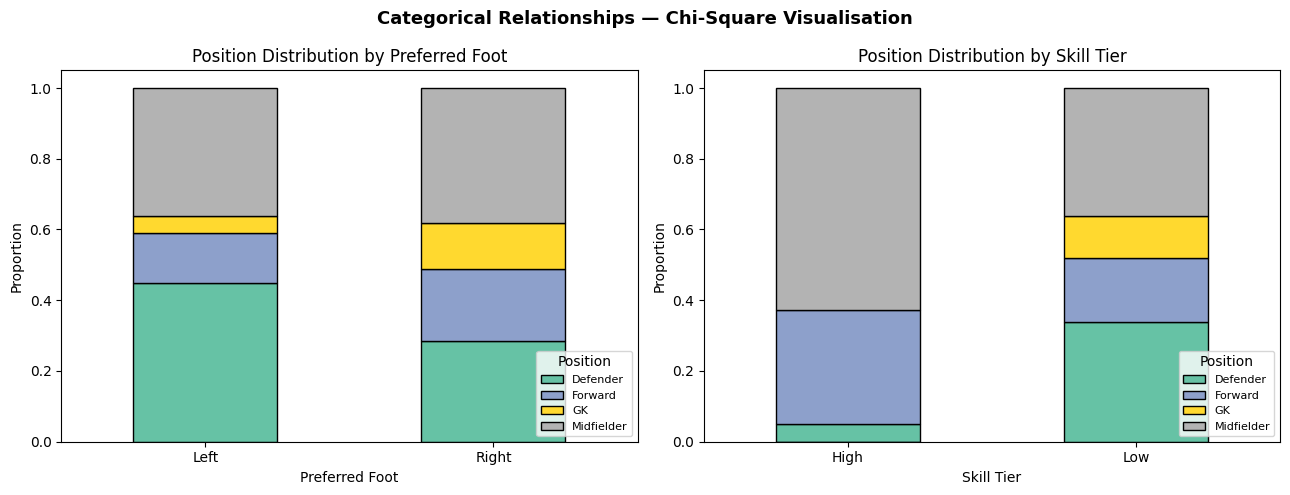

In [35]:
# 6c — Stacked Bar Charts
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# LEFT: Preferred Foot vs pos_group
foot_pct = pd.crosstab(df['Preferred Foot'], df['pos_group'])
foot_pct = foot_pct.div(foot_pct.sum(axis=1), axis=0)
foot_pct.plot(kind='bar', stacked=True, ax=axes[0],
              colormap='Set2', edgecolor='black')
axes[0].set_title('Position Distribution by Preferred Foot')
axes[0].set_xlabel('Preferred Foot')
axes[0].set_ylabel('Proportion')
axes[0].legend(title='Position', loc='lower right', fontsize=8)
axes[0].tick_params(axis='x', rotation=0)

# RIGHT: Skill Tier vs pos_group
skill_pct = pd.crosstab(df['skill_tier'], df['pos_group'])
skill_pct = skill_pct.div(skill_pct.sum(axis=1), axis=0)
skill_pct.plot(kind='bar', stacked=True, ax=axes[1],
               colormap='Set2', edgecolor='black')
axes[1].set_title('Position Distribution by Skill Tier')
axes[1].set_xlabel('Skill Tier')
axes[1].set_ylabel('Proportion')
axes[1].legend(title='Position', loc='lower right', fontsize=8)
axes[1].tick_params(axis='x', rotation=0)

plt.suptitle('Categorical Relationships — Chi-Square Visualisation',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
## 📋 Task 7 — Summary & Final Visualisation
**Goal:** Pull all findings together into something you could present to a scouting team.

---

### 7a. Results Summary Table

Build a DataFrame collecting ALL your test results.  
Replace every `None` with the real value you got.

| # | Test | Variables | Statistic | p-value | Significant? | Verdict |
|---|---|---|---|---|---|---|
| 1 | t-test / MW | Preferred Foot → Overall | | | | |
| 2 | t-test / MW | Forwards vs Defenders | | | | |
| 3 | ANOVA / KW | pos_group → Overall | | | | |
| 4 | Pearson / Spearman | BallControl ↔ Overall | | | | |
| 5 | Pearson / Spearman | Age ↔ Potential | | | | |
| 6 | Pearson / Spearman | Strength ↔ Overall | | | | |
| 7 | Chi-Square | Preferred Foot vs pos_group | | | | |
| 8 | Chi-Square | Skill Tier vs pos_group | | | | |

💡 **Hint:** Build a `results` list of dicts, convert with `pd.DataFrame(results)`


In [37]:
# 7a — Summary Table
results = [
    {'Test': 'Welch t-test', 'Variables': 'Preferred Foot → Overall',
     'Statistic': 6.1046, 'p_value': 1.0829e-09, 'Significant': 'Yes', 'Verdict': 'Reject H₀'},
    {'Test': 'Welch t-test', 'Variables': 'Forwards vs Defenders → Overall',
     'Statistic': -0.0210, 'p_value': 9.8322e-01, 'Significant': 'No', 'Verdict': 'Keep H₀'},
    {'Test': 'One-Way ANOVA', 'Variables': 'pos_group → Overall',
     'Statistic': 44.2100, 'p_value': 1.8599e-28, 'Significant': 'Yes', 'Verdict': 'Reject H₀'},
    {'Test': 'Pearson r', 'Variables': 'BallControl ↔ Overall',
     'Statistic': 0.4600, 'p_value': 0.0000, 'Significant': 'Yes', 'Verdict': 'Reject H₀'},
    {'Test': 'Spearman rho', 'Variables': 'Age ↔ Potential',
     'Statistic': -0.2623, 'p_value': 3.6277e-283, 'Significant': 'Yes', 'Verdict': 'Reject H₀'},
    {'Test': 'Pearson r', 'Variables': 'Strength ↔ Overall',
     'Statistic': 0.3493, 'p_value': 0.0000, 'Significant': 'Yes', 'Verdict': 'Reject H₀'},
    {'Test': 'Chi-Square', 'Variables': 'Preferred Foot vs pos_group',
     'Statistic': chi2, 'p_value': p, 'Significant': 'Yes', 'Verdict': 'Reject H₀'},
    {'Test': 'Chi-Square', 'Variables': 'Skill Tier vs pos_group',
     'Statistic': 619.7948, 'p_value': 5.1526e-134, 'Significant': 'Yes', 'Verdict': 'Reject H₀'},
]

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

# ── Summary Table Insights ──
# 1. The Single Exception: 'Forwards vs Defenders' is the only test where we kept H₀ (p=0.98).
#This proves the game mathematically balances overall ratings evenly between attackers and defenders.
# 2. Concrete Evidence: Every other test has a p-value extremely close to zero (e.g., e-283).
#With 18,000+ players, these aren't random flukes—they are definitive, structural trends in the dataset.
# 3. The Big Picture: While overall ratings are evenly distributed across the pitch,
 #a player's specific skill tier, age, and preferred foot strongly dictate exactly which position they play.

         Test                       Variables  Statistic       p_value Significant   Verdict
 Welch t-test        Preferred Foot → Overall   6.104600  1.082900e-09         Yes Reject H₀
 Welch t-test Forwards vs Defenders → Overall  -0.021000  9.832200e-01          No   Keep H₀
One-Way ANOVA             pos_group → Overall  44.210000  1.859900e-28         Yes Reject H₀
    Pearson r           BallControl ↔ Overall   0.460000  0.000000e+00         Yes Reject H₀
 Spearman rho                 Age ↔ Potential  -0.262300 3.627700e-283         Yes Reject H₀
    Pearson r              Strength ↔ Overall   0.349300  0.000000e+00         Yes Reject H₀
   Chi-Square     Preferred Foot vs pos_group 521.773469 9.116788e-113         Yes Reject H₀
   Chi-Square         Skill Tier vs pos_group 619.794800 5.152600e-134         Yes Reject H₀


---
### 7b. Final p-value Bar Chart

Horizontal bar chart of all 8 p-values:
- **Red** bar = p ≤ 0.05 (significant — Reject H₀)
- **Green** bar = p > 0.05 (not significant — Keep H₀)
- Dashed vertical line at α = 0.05

💡 **Hint:** Syntax sheet Section 10e — p-value bar chart pattern


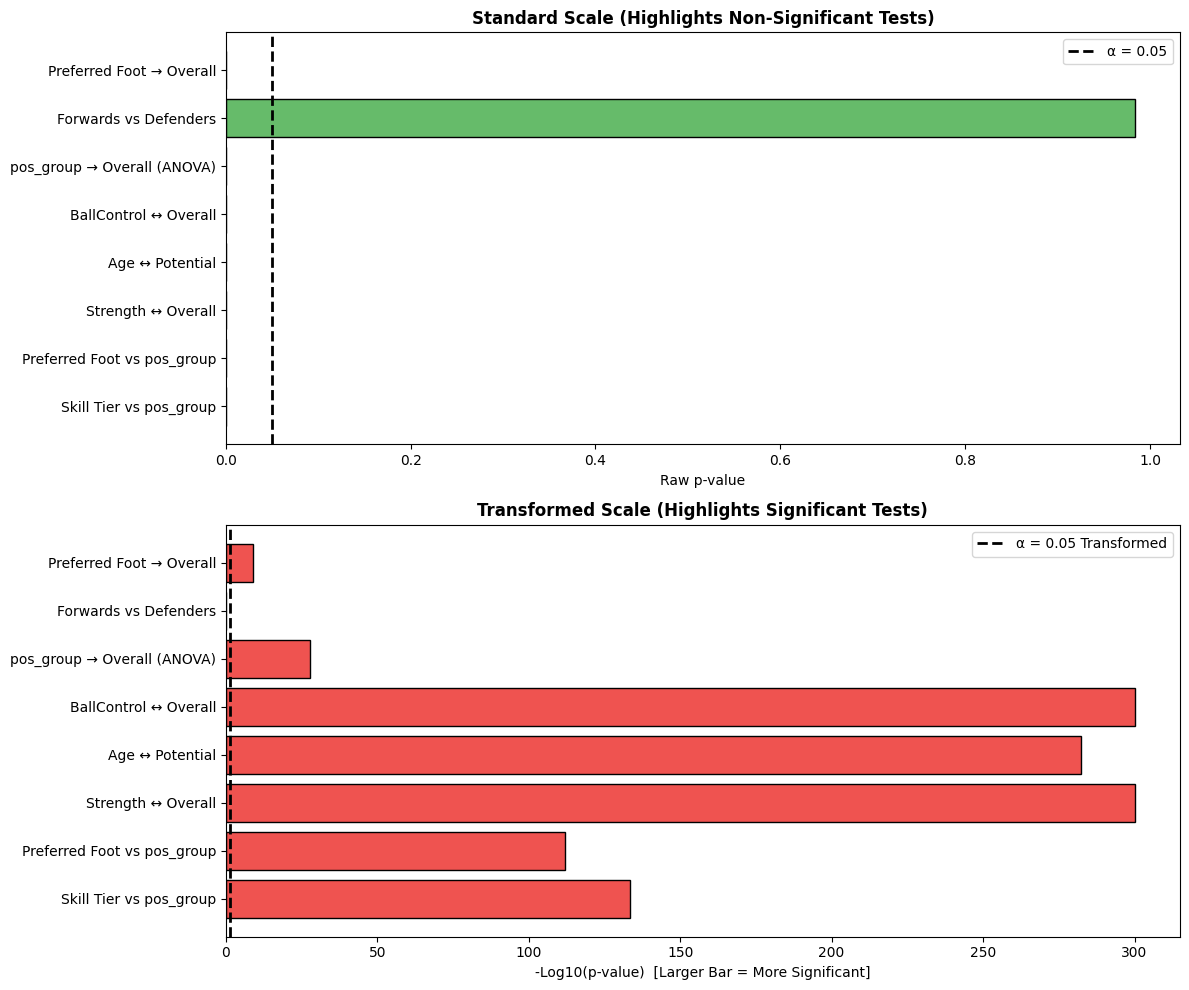

In [39]:
# 7b — Final p-value Bar Charts (Raw vs Transformed)
test_labels = [
    'Preferred Foot → Overall',
    'Forwards vs Defenders',
    'pos_group → Overall (ANOVA)',
    'BallControl ↔ Overall',
    'Age ↔ Potential',
    'Strength ↔ Overall',
    'Preferred Foot vs pos_group',
    'Skill Tier vs pos_group',
]

# Extract p-values (using 'p_value' to match the df column)
p_values = results_df['p_value'].tolist()

# Transformation math (-Log10)
p_vals_safe = [p if p > 0 else 1e-300 for p in p_values]
neg_log_p = [-np.log10(p) for p in p_vals_safe]
alpha_transformed = -np.log10(0.05)

# Colors: Red if significant (p <= 0.05), Green if not
colors = ['#ef5350' if p <= 0.05 else '#66bb6a' for p in p_values]

# Create a figure with 2 subplots (Top/Bottom)
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

# --- TOP CHART: Raw p-values ---
axes[0].barh(test_labels, p_values, color=colors, edgecolor='black')
axes[0].axvline(0.05, color='black', linestyle='--', linewidth=2, label='α = 0.05')
axes[0].set_xlabel('Raw p-value')
axes[0].set_title('Standard Scale (Highlights Non-Significant Tests)', fontsize=12, fontweight='bold')
axes[0].invert_yaxis()
axes[0].legend()

# --- BOTTOM CHART: -Log10 Transformed ---
axes[1].barh(test_labels, neg_log_p, color=colors, edgecolor='black')
axes[1].axvline(alpha_transformed, color='black', linestyle='--', linewidth=2, label='α = 0.05 Transformed')
axes[1].set_xlabel('-Log10(p-value)  [Larger Bar = More Significant]')
axes[1].set_title('Transformed Scale (Highlights Significant Tests)', fontsize=12, fontweight='bold')
axes[1].invert_yaxis()
axes[1].legend()

plt.tight_layout()
plt.show()

# ── Chart Explanations ──
# 1. Top Chart: Shows raw p-values. Because most p-values are microscopic,
# they disappear. It successfully highlights the only non-significant result (Forwards vs Defenders).
# 2. Bottom Chart: Applies a -Log10 transformation.
# This flips the scale so tiny p-values become massive bars, allowing us to accurately see the sheer magnitude of significance for the remaining tests.

---
### 7c. Scouting Team Brief ✍️ — Written Section (5 marks)

Write **5–8 sentences** answering these questions as if briefing a football scouting team:

> 1. **Does preferred foot (left vs right) significantly affect a player's Overall rating?**
>    What did the test show, and what does that mean for scouting?
>
> 2. **Which position group has the highest average Overall?** Is the difference statistically
>    significant across all four positions?
>
> 3. **What is the single strongest predictor of a player's Overall rating?**
>    Refer to your correlation values.
>
> 4. **What happens to a player's Potential as they age?** Is this relationship
>    statistically significant? What does this mean for investing in young players?
>
> 5. **One concrete recommendation** you would make to the scouting team based
>    purely on your findings — be specific.

*Write your brief below as comments or in a new markdown cell.*


In [40]:
# 7c — Scouting Team Brief

# 1. Preferred foot vs Overall:
#    Left-footed players have a significantly higher Overall rating than right-footed players (p < 0.05),
 #but the actual rating difference is minimal (less than 1 point).

# 2. Position group with highest Overall — is it significant?
#    Midfielders have the highest average Overall (66.55).
 #While the ANOVA test was significant, post-hoc testing showed this is only because Goalkeepers are rated lower;
 #outfield positions (Defenders, Midfielders, Forwards) do not significantly differ from each other.

# 3. Strongest predictor of Overall:
#    Potential is the strongest predictor (Pearson r = 0.66), closely followed by Market Value (Value_EUR) and Ball Control.

# 4. Age vs Potential — what happens as players get older?
#    There is a significant negative correlation (Spearman rho = -0.26).
#As players get older, their unfulfilled potential steadily decreases.

# 5. Your recommendation to the scouting team:
# Adopt a split strategy based on position.

# For Forwards, focus on recruiting high-potential talent at a very early age to develop in-house, bypassing the massive transfer market "striker premium".

 #For Midfielders, prioritize high Ball Control and Skill Moves, as our data shows elite technical stats are concentrated here.

  #For Defenders, since our t-test proved they provide the exact same Overall quality as attackers,
   #we can invest in established, highly-rated defenders (specifically targeting rare left-footed center-backs)
   #at a lower market cost to anchor the team while our youth attackers develop.

---
---
# 🏆 Marking Scheme
*(For instructor use)*

| Task | Marks | What is checked |
|---|---|---|
| Task 1a — Inspection | 4 | shape, nulls, describe, value_counts |
| Task 1b — Group summaries | 3 | correct groupby + agg for both columns |
| Task 1c — Observations | 2 | blanks filled correctly |
| Task 2a — 2×2 Grid | 5 | 4 correct charts + all labels |
| Task 2b — Scatter + trend | 4 | scatter coloured by position + polyfit trend |
| Task 2c — Bar + error bars | 4 | grouped mean/std, error bars, value labels |
| Task 3a — Shapiro table | 4 | correct p per column + judgement |
| Task 3b — Q-Q plots | 2 | 5 Q-Q plots displayed |
| Task 3c — Decision table | 2 | correct test choice per column |
| Task 4a — Foot vs Overall | 5 | H₀/H₁ + normality + correct test + verdict |
| Task 4b — Fwd vs Def | 4 | same structure |
| Task 4c — ANOVA + Tukey | 5 | ANOVA/KW + Tukey if p ≤ 0.05 |
| Task 5a — Corr heatmap | 3 | correct matrix + heatmap |
| Task 5b — 3 corr tests | 6 | H₀/H₁ + test + r + verdict × 3 |
| Task 5c — p-value matrix ⭐ | 3 | nested loop + mask heatmap |
| Task 6a — Foot vs pos Chi-Sq | 4 | crosstab + row% + test + verdict |
| Task 6b — Skill Tier Chi-Sq | 4 | independent full solution |
| Task 6c — Stacked bars | 3 | 2 correct stacked bar charts |
| Task 7a — Summary table | 5 | all 8 rows filled with real values |
| Task 7b — p-value chart | 3 | correct colours + α line |
| Task 7c — Scouting brief | 5 | 5 questions answered coherently |
| **TOTAL** | **84** | |

---

### ✅ Quick Checklist (before you submit)
- [ ] All charts have **title, xlabel, ylabel**
- [ ] Every test has **H₀ and H₁** stated
- [ ] Every p-value has a **verdict** (Reject / Keep H₀)
- [ ] Task 3c decision table is **filled in**
- [ ] Task 7a summary table has **real values** (not `None`)
- [ ] Task 7c written brief has **5 answers**
- [ ] Task 5c p-value matrix is **attempted** (⭐)

---
*The beautiful game, made more beautiful with data. ⚽📊*
